# Checkpoint 02 — APIs, energias renováveis e aprendizado de máquina

# Avaliação — APIs de energia renovável e aprendizado de máquina

Consulte duas APIs públicas, organize os dados e resolva **duas tarefas**: classificar a fonte de empreendimentos da ANEEL e estimar a radiação solar em Petrolina (PE). Em **cada tarefa**, treine e compare **três algoritmos diferentes**. Este notebook fornece a consulta às APIs e os arquivos de dados; **você implementará a análise e os modelos**.

**Entrega:** um único link para um repositório público no GitHub com notebook executável, arquivos de dados, README e resultados. As instruções completas estão ao final e no enunciado separado.

## O que é recebido da API?

Uma requisição HTTP `GET` pede dados a uma URL. Os parâmetros identificam o recurso, o período e as variáveis. A resposta é **JSON**: um objeto com chaves e valores. Nas duas consultas desta avaliação, o acesso público **não exige login, token ou chave de API**. Se outra API exigir credenciais, não as publique no repositório.

Este código usa somente `json`, `urllib` e `csv`, bibliotecas que vêm com Python. `csv` serve apenas para exportar os dados recebidos; os imports para análise, tabelas, gráficos e ML são parte da sua implementação.

In [ ]:
import json
import urllib.parse
import urllib.request
import csv

A função a seguir monta a URL, abre a conexão, verifica o status HTTP e converte o JSON. Se houver falha na rede ou na API, exibe uma mensagem de erro.

In [ ]:
def consultar_api(endereco, parametros):
    url = endereco + "?" + urllib.parse.urlencode(parametros)
    try:
        with urllib.request.urlopen(url, timeout=100) as resposta:
            return json.load(resposta)
    except Exception as erro:
        raise RuntimeError(f"Não foi possível consultar a API: {erro}") from erro

# Tarefa 1 — Classificação (ANEEL)

**Pergunta:** a partir da potência e da localização de um empreendimento, é possível classificar sua fonte como **Solar, Eólica ou Hidráulica**?

A fonte é uma **categoria**: o problema é de classificação. O conjunto [SIGA da ANEEL](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel) registra empreendimentos em várias fases. Usamos `UFV` (solar fotovoltaica), `EOL` (eólica) e três categorias hidráulicas: `UHE`, `PCH`, `CGH`. Estas três últimas formarão uma única classe, *Hidráulica*. A tarefa trata da **categoria do cadastro**, não da quantidade de energia gerada.

### Atributos originais da resposta

| Campo da API | Significado | Uso na tarefa |
|---|---|---|
| `SigTipoGeracao` | Sigla do tipo de geração (`UFV`, `EOL`, `UHE`, `PCH`, `CGH`) | Origina o alvo `fonte`; **não entra em X** |
| `MdaPotenciaOutorgadaKw` | Potência outorgada do empreendimento, em quilowatts (kW) | Entrada `potencia_kw`; potência nominal autorizada, não energia produzida |
| `NumCoordNEmpreendimento` | Latitude aproximada do empreendimento, em graus decimais | Entrada `latitude` |
| `NumCoordEEmpreendimento` | Longitude aproximada do empreendimento, em graus decimais | Entrada `longitude` |
| `CodCEG`, `NomEmpreendimento` e campos de combustível | Código, nome e descrição associados ao empreendimento e à fonte | **Não usar como entradas**: podem revelar a classe |

A resposta CKAN contém `success` e `result`; dentro de `result`, `records` são as linhas, `fields` descrevem as colunas e `total` indica o total encontrado para o filtro. O CSV final terá **três atributos numéricos e a classe**. Quantidades consultadas têm limite por tipo e não representam a participação de cada fonte na matriz brasileira.

### 1. Consultar a ANEEL

O recurso SIGA é acessado pela API pública CKAN/DataStore. `resource_id` aponta para o conjunto; `filters` seleciona uma sigla; `limit` limita o retorno de cada pedido. Não há etapa de autenticação para esta consulta pública.

In [ ]:
URL_ANEEL = "https://dadosabertos.aneel.gov.br/api/3/action/datastore_search"
ID_RECURSO = "11ec447d-698d-4ab8-977f-b424d5deee6a"
SIGLAS = ["UFV", "EOL", "UHE", "PCH", "CGH"]
print("API ANEEL: consulta pública, sem token")

In [ ]:
registros_aneel = []
for sigla in SIGLAS:
    parametros = {
        "resource_id": ID_RECURSO,
        "filters": json.dumps({"SigTipoGeracao": sigla}),
        "limit": 1200,
    }
    resposta = consultar_api(URL_ANEEL, parametros)
    if not resposta.get("success"):
        raise ValueError(f"Consulta da ANEEL falhou para {sigla}")
    linhas = resposta["result"]["records"]
    print(f"{sigla}: {len(linhas)} linhas recebidas")
    registros_aneel.extend(linhas)
print("Total de linhas recebidas:", len(registros_aneel))

### 2. Gerar o CSV para a tarefa

A API pode fornecer números como texto, inclusive com vírgula decimal. O tratamento abaixo converte esses valores, descarta linhas sem potência ou coordenadas e transforma as siglas em três classes. Cada linha do arquivo final representa **um empreendimento**. Confira a quantidade de exemplos por classe durante sua análise; se necessário, discuta o desequilíbrio entre classes.

In [ ]:
def numero(valor):
    texto = str(valor).strip()
    if "," in texto:
        texto = texto.replace(".", "").replace(",", ".")
    try:
        return float(texto)
    except ValueError:
        return None

fontes = {"UFV": "Solar", "EOL": "Eólica", "UHE": "Hidráulica",
          "PCH": "Hidráulica", "CGH": "Hidráulica"}
linhas_classificacao = []
for registro in registros_aneel:
    potencia = numero(registro.get("MdaPotenciaOutorgadaKw"))
    latitude = numero(registro.get("NumCoordNEmpreendimento"))
    longitude = numero(registro.get("NumCoordEEmpreendimento"))
    fonte = fontes.get(registro.get("SigTipoGeracao"))
    if fonte and all(valor is not None for valor in (potencia, latitude, longitude)):
        linhas_classificacao.append([potencia, latitude, longitude, fonte])
if len(linhas_classificacao) < 90:
    raise ValueError("Poucos registros válidos: confira a resposta da ANEEL")
print("Linhas válidas:", len(linhas_classificacao))
print("Primeiro exemplo:", linhas_classificacao[0])

In [ ]:
with open("aneel_classificacao_orange.csv", "w", newline="", encoding="utf-8-sig") as arquivo:
    escritor = csv.writer(arquivo)
    escritor.writerow(["potencia_kw", "latitude", "longitude", "fonte"])
    escritor.writerows(linhas_classificacao)
print("Salvo: aneel_classificacao_orange.csv")

### O que você deve fazer — classificação

1. Carregue o CSV, confira os tipos das colunas, as contagens por classe, valores ausentes e distribuições relevantes. Explique `X` (três entradas) e `y` (`fonte`).
2. Faça uma divisão **estratificada** de treino/teste, por exemplo 80%/20%, com semente fixa. Ajustes de escala aprendidos dos dados devem ser feitos **somente com o treino**.
3. Escolha, justifique e treine **três classificadores diferentes** usando a mesma divisão. Eles **não estão importados nem implementados** neste notebook.
4. Compare Accuracy, Precision, Recall e F1. Declare o tipo de média usado nas métricas por classe (por exemplo, `macro`) e apresente a matriz de confusão.
5. Explique qual modelo escolheria, quais classes ele mais confunde e por que potência/localização podem não bastar para uma aplicação real. Não use `SigTipoGeracao`, nomes, CEG ou descrições da fonte como entradas.

**O que registrar:** tabela comparativa dos três algoritmos, gráfico(s) ou matriz de confusão e interpretação escrita.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Para classificação: KNN, Regressão Logística, Random Forest
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Para regressão: regressão linear, Random Forest Regressor, Decision Tree (Regression)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

# Para classificação
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
# Para regressão
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Caso a consulta da API falhar:
# dados = pd.read_csv('https://raw.githubusercontent.com/prof-atritiack/CHECKPOINT_02_SERS_1CC_2SEM/refs/heads/main/aneel_classificacao_orange.csv')
# dados.head(20)

Dimensão: (3876, 4)

Tipos das colunas:
 potencia_kw    float64
latitude       float64
longitude      float64
fonte              str
dtype: object

Valores ausentes:
 potencia_kw    0
latitude       0
longitude      0
fonte          0
dtype: int64

Distribuição das classes:
 fonte
Hidráulica    1476
Solar         1200
Eólica        1200
Name: count, dtype: int64

Resumo das entradas:
         potencia_kw     latitude    longitude
count  3.876000e+03  3876.000000  3876.000000
mean   4.201468e+04   -12.693951   -46.158299
std    3.016366e+05     9.500523     8.357453
min    1.600000e-01   -33.722806   -69.941389
25%    4.400000e+02   -21.142110   -52.561817
50%    1.268000e+04   -10.469532   -47.393697
75%    3.000000e+04    -4.127788   -41.280013
max    1.123310e+07     3.831392     0.000000


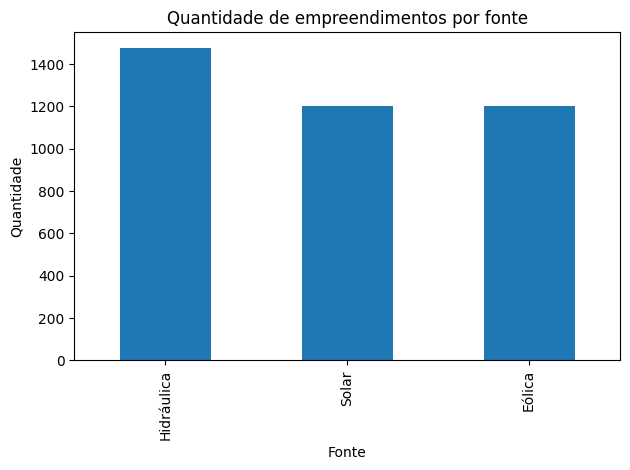

In [2]:
# Carregamento e exploração dos dados de classificação
dados = pd.read_csv("aneel_classificacao_orange.csv")
print("Dimensão:", dados.shape)
print("\nTipos das colunas:\n", dados.dtypes)
print("\nValores ausentes:\n", dados.isna().sum())
print("\nDistribuição das classes:\n", dados["fonte"].value_counts())
print("\nResumo das entradas:\n", dados[["potencia_kw", "latitude", "longitude"]].describe())

# Visualização da distribuição das classes
dados["fonte"].value_counts().plot(kind="bar", title="Quantidade de empreendimentos por fonte")
plt.xlabel("Fonte")
plt.ylabel("Quantidade")
plt.tight_layout()
plt.show()


In [3]:
# X contém somente as três entradas permitidas; y é a classe que queremos prever.
X = dados[["potencia_kw", "latitude", "longitude"]]
y = dados["fonte"]

# Divisão 80/20 estratificada para manter a proporção das classes.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Treino:", X_treino.shape, "Teste:", X_teste.shape)


Treino: (3100, 3) Teste: (776, 3)


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# KNN e Regressão Logística dependem da escala das variáveis. O scaler fica
# dentro do Pipeline para ser ajustado somente com o conjunto de treino.
modelos_classificacao = {
    "KNN": Pipeline([
        ("padronizacao", StandardScaler()),
        ("modelo", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Regressão Logística": Pipeline([
        ("padronizacao", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=2000, random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42)
}

resultados_classificacao = []
previsoes_classificacao = {}
for nome, modelo in modelos_classificacao.items():
    modelo.fit(X_treino, y_treino)
    previsto = modelo.predict(X_teste)
    previsoes_classificacao[nome] = previsto
    resultados_classificacao.append({
        "Algoritmo": nome,
        "Accuracy": accuracy_score(y_teste, previsto),
        "Precision (weighted)": precision_score(y_teste, previsto, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_teste, previsto, average="weighted", zero_division=0),
        "F1 (weighted)": f1_score(y_teste, previsto, average="weighted", zero_division=0)
    })

tabela_classificacao = pd.DataFrame(resultados_classificacao).sort_values("F1 (weighted)", ascending=False)
display(tabela_classificacao.round(4))
print("As métricas multiclasses Precision, Recall e F1 usam média weighted.")


,Algoritmo,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted)
2,Random Forest,0.9755,0.9759,0.9755,0.9755
0,KNN,0.9652,0.9655,0.9652,0.9651
1,Regressão Logística,0.8247,0.8313,0.8247,0.8233


As métricas multiclasses Precision, Recall e F1 usam média weighted.


In [5]:
# Matrizes de confusão dos três classificadores
classes = ["Solar", "Eólica", "Hidráulica"]
for nome, previsto in previsoes_classificacao.items():
    matriz = confusion_matrix(y_teste, previsto, labels=classes)
    print(f"\nMatriz de confusão - {nome}")
    display(pd.DataFrame(matriz, index=[f"Real: {c}" for c in classes], columns=[f"Prev.: {c}" for c in classes]))



Matriz de confusão - KNN


,Prev.: Solar,Prev.: Eólica,Prev.: Hidráulica
Real: Solar,226,6,8
Real: Eólica,3,231,6
Real: Hidráulica,3,1,292



Matriz de confusão - Regressão Logística


,Prev.: Solar,Prev.: Eólica,Prev.: Hidráulica
Real: Solar,167,51,22
Real: Eólica,8,216,16
Real: Hidráulica,19,20,257



Matriz de confusão - Random Forest


,Prev.: Solar,Prev.: Eólica,Prev.: Hidráulica
Real: Solar,228,5,7
Real: Eólica,1,235,4
Real: Hidráulica,0,2,294


### Interpretação da classificação

**Modelo escolhido: Random Forest** (Accuracy 0,976; F1 weighted 0,975), seguido de perto pelo KNN. A Regressão Logística foi bem pior (Accuracy 0,825) porque sua fronteira de decisão é linear, e a relação entre potência, latitude/longitude e fonte não é linear.

**Classes mais confundidas.**
- No Random Forest os erros são poucos (19 em 776) e bem distribuídos: Solar → Hidráulica (7), Solar → Eólica (5), Eólica → Hidráulica (4), Hidráulica → Eólica (2), Eólica → Solar (1). A classe com mais erros é **Solar** (12 de 240 previstos errados); a **Hidráulica** é a mais fácil (294 de 296 corretos).
- Na Regressão Logística o erro dominante é **Solar → Eólica** (51 de 240), seguido de Solar → Hidráulica (22) e Hidráulica → Eólica (20).

**Limitações.** Potência e localização não determinam a tecnologia: usinas de fontes diferentes podem ter porte parecido e estar na mesma região (por exemplo, no Nordeste há muitos parques eólicos e solares). Além disso, o cadastro mistura empreendimentos em várias fases e a potência é a *outorgada* (autorizada), não a energia gerada. Em uma aplicação real seria preciso incluir outras informações do projeto.

**Atenção aos dados.** 47 linhas têm latitude e longitude iguais a `0,0` (coordenada ausente preenchida com zero), todas de Eólica ou Hidráulica e nenhuma de Solar. Isso pode dar uma pista artificial ao modelo; o tratamento ideal seria descartar essas linhas ou tratá-las como ausentes. Mantivemos o CSV como foi gerado para que os resultados sigam reprodutíveis. Também há 28 linhas duplicadas.


# Tarefa 2 — Regressão (Open-Meteo)

**Pergunta:** dadas as condições meteorológicas e a hora local em Petrolina (PE), qual é a radiação solar horizontal média naquela hora? A resposta é um **número**, então o problema é de regressão.

A API histórica do [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api) devolve dados horários para coordenadas e período escolhidos. Usamos **1º de abril a 30 de junho de 2025**, em horário local. São dados históricos estimados por modelos/reanálise, não leituras de um sensor particular. **Radiação em W/m² não equivale à energia em kWh nem à geração de um painel.**

### Parâmetros da requisição

| Parâmetro | Valor nesta avaliação | Significado |
|---|---|---|
| `latitude`, `longitude` | `-9.39`, `-40.50` | Coordenadas aproximadas de Petrolina (PE) |
| `start_date`, `end_date` | `2025-04-01`, `2025-06-30` | Período histórico consultado, inclusive as datas extremas |
| `timezone` | `America/Recife` | Faz `time` representar a hora local |
| `hourly` | Lista das cinco variáveis abaixo | Solicita valores horários em JSON |

### Atributos do conjunto de dados

| Campo da API → CSV | Significado e unidade | Uso na tarefa |
|---|---|---|
| `time` → `data_hora` | Data e hora local de cada registro | Ordenar e separar por tempo; não é entrada em X |
| `temperature_2m` → `temperatura_c` | Temperatura do ar a 2 m, em °C | Entrada |
| `relative_humidity_2m` → `umidade_pct` | Umidade relativa a 2 m, em % | Entrada |
| `cloud_cover` → `nuvens_pct` | Cobertura total de nuvens, em % | Entrada |
| `wind_speed_10m` → `vento_kmh` | Velocidade do vento a 10 m, em km/h | Entrada |
| `time` → `hora` | Hora local extraída da data, de 7 a 17 nesta amostra | Entrada |
| `shortwave_radiation` → `radiacao_w_m2` | Radiação solar global horizontal média da hora anterior, em W/m² | Alvo numérico `y`; **não entra em X** |

A resposta inclui `hourly` (listas dos valores, alinhadas por índice), `hourly_units` (unidades) e metadados da localização. Cada linha do CSV final representa **uma hora entre 7h e 17h**; esse recorte reduz o domínio de horas noturnas, mas não remove a importância da hora para a previsão.

### 3. Consultar o histórico meteorológico

A chamada usa GET, sem cadastro ou chave para esta consulta pública de uso educacional. Se `hourly` faltar, verifique datas e parâmetros.

In [ ]:
URL_METEO = "https://archive-api.open-meteo.com/v1/archive"
parametros_meteo = {
    "latitude": -9.39,
    "longitude": -40.50,
    "start_date": "2025-04-01",
    "end_date": "2025-06-30",
    "timezone": "America/Recife",
    "hourly": ",".join(["temperature_2m", "relative_humidity_2m",
                         "cloud_cover", "wind_speed_10m", "shortwave_radiation"]),
}
print("Open-Meteo: consulta pública, sem token")

In [ ]:
resposta_meteo = consultar_api(URL_METEO, parametros_meteo)
if "hourly" not in resposta_meteo:
    raise ValueError("Resposta sem a seção hourly")
horas_api = resposta_meteo["hourly"]
print("Campos recebidos:", list(horas_api))
print("Unidades informadas pela API:", resposta_meteo.get("hourly_units", {}))
print("Quantidade de horários:", len(horas_api["time"]))

### 4. Gerar o CSV horário

As listas de `hourly` são alinhadas: o índice 0 de cada variável se refere ao índice 0 de `time`. Percorremos esses índices, mantemos as horas de 7h a 17h e descartamos linhas com valores ausentes. A data permanece ordenada para facilitar uma avaliação temporal.

In [ ]:
nomes_api = ["temperature_2m", "relative_humidity_2m", "cloud_cover",
             "wind_speed_10m", "shortwave_radiation"]
linhas_regressao = []
for indice, data_hora in enumerate(horas_api["time"]):
    hora = int(data_hora[11:13])
    valores = [horas_api[nome][indice] for nome in nomes_api]
    if 7 <= hora <= 17 and all(valor is not None for valor in valores):
        linhas_regressao.append([data_hora, *valores[:4], hora, valores[4]])
if len(linhas_regressao) < 100:
    raise ValueError("Poucos horários válidos: confira a resposta do Open-Meteo")
print("Horas válidas:", len(linhas_regressao))
print("Primeiro exemplo:", linhas_regressao[0])

In [ ]:
with open("meteo_regressao_orange.csv", "w", newline="", encoding="utf-8-sig") as arquivo:
    escritor = csv.writer(arquivo)
    escritor.writerow(["data_hora", "temperatura_c", "umidade_pct",
                       "nuvens_pct", "vento_kmh", "hora", "radiacao_w_m2"])
    escritor.writerows(linhas_regressao)
print("Salvo: meteo_regressao_orange.csv")

### O que você deve fazer — regressão

1. Carregue o CSV, explique as colunas, examine valores ausentes e apresente ao menos uma visualização. Defina `X` (cinco entradas) e `y` (`radiacao_w_m2`).
2. Mantenha as linhas em ordem de `data_hora`: use aproximadamente **80% das primeiras horas para treino** e as 20% finais para teste. Evite embaralhar as horas. Ajuste transformações apenas com o treino.
3. Escolha, justifique e treine **três algoritmos de regressão diferentes** com a mesma divisão. Os imports e a implementação são sua responsabilidade.
4. Compare **MAE** (W/m²), **MSE** ((W/m²)²) e **R²**; faça um gráfico de valores reais × previstos de pelo menos um modelo.
5. Interprete os erros, discuta o peso da hora e explique por que essa estimativa da radiação **não prevê automaticamente a energia produzida** por um sistema fotovoltaico.

**O que registrar:** tabela comparativa dos três algoritmos, gráfico e interpretação escrita. Nenhum valor de `radiacao_w_m2` deve ser usado para criar uma entrada do mesmo registro.

### Desenvolvimento da regressão

A divisão abaixo é temporal: as primeiras 80% das observações são usadas para treino e as últimas 20% para teste, sem embaralhamento.


In [ ]:
# Carregamento, ordenação e exploração dos dados meteorológicos
meteo = pd.read_csv("meteo_regressao_orange.csv")
meteo["data_hora"] = pd.to_datetime(meteo["data_hora"])
meteo = meteo.sort_values("data_hora").reset_index(drop=True)
print("Dimensão:", meteo.shape)
print("\nValores ausentes:\n", meteo.isna().sum())
print("\nResumo das variáveis:\n", meteo.describe(numeric_only=True))

# Visualização pedida: comportamento médio da radiação conforme a hora do dia
media_hora = meteo.groupby("hora")["radiacao_w_m2"].mean()
media_hora.plot(marker="o", title="Radiação solar média por hora do dia")
plt.xlabel("Hora local")
plt.ylabel("Radiação média (W/m²)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# data_hora é apenas identificação e radiacao_w_m2 é o alvo, portanto não entram em X.
entradas_regressao = ["temperatura_c", "umidade_pct", "nuvens_pct", "vento_kmh", "hora"]
X_reg = meteo[entradas_regressao]
y_reg = meteo["radiacao_w_m2"]

corte = int(len(meteo) * 0.80)
X_treino_reg, X_teste_reg = X_reg.iloc[:corte], X_reg.iloc[corte:]
y_treino_reg, y_teste_reg = y_reg.iloc[:corte], y_reg.iloc[corte:]
print("Treino:", len(X_treino_reg), "horas | Teste:", len(X_teste_reg), "horas")
print("Teste de", meteo.iloc[corte]["data_hora"], "até", meteo.iloc[-1]["data_hora"])


In [ ]:
modelos_regressao = {
    "Regressão Linear": Pipeline([
        ("padronizacao", StandardScaler()),
        ("modelo", LinearRegression())
    ]),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=300, random_state=42),
    "Árvore de Decisão": DecisionTreeRegressor(random_state=42)
}

resultados_regressao = []
previsoes_regressao = {}
for nome, modelo in modelos_regressao.items():
    modelo.fit(X_treino_reg, y_treino_reg)
    previsto = modelo.predict(X_teste_reg)
    previsoes_regressao[nome] = previsto
    resultados_regressao.append({
        "Algoritmo": nome,
        "MAE (W/m²)": mean_absolute_error(y_teste_reg, previsto),
        "MSE ((W/m²)²)": mean_squared_error(y_teste_reg, previsto),
        "R²": r2_score(y_teste_reg, previsto)
    })

tabela_regressao = pd.DataFrame(resultados_regressao).sort_values("MAE (W/m²)")
display(tabela_regressao.round(3))


In [ ]:
# Gráfico real x previsto para os três modelos no mesmo período de teste
plt.figure(figsize=(12, 5))
plt.plot(meteo.iloc[corte:]["data_hora"], y_teste_reg.values, label="Real", linewidth=2)
for nome, previsto in previsoes_regressao.items():
    plt.plot(meteo.iloc[corte:]["data_hora"], previsto, label=nome, alpha=0.75)
plt.title("Radiação solar: valores reais x previstos")
plt.xlabel("Data/hora")
plt.ylabel("Radiação (W/m²)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Interpretação:")
print("A hora do dia é importante porque a posição do Sol muda ao longo do dia, produzindo um ciclo diário claro de radiação.")
print("Nuvens, temperatura, umidade e vento acrescentam informações sobre as condições meteorológicas associadas à radiação.")
print("Estimar radiação não é o mesmo que prever geração elétrica: a geração de um sistema fotovoltaico também depende de potência instalada, orientação e inclinação dos módulos, eficiência, temperatura dos painéis, perdas, sombreamento e disponibilidade do equipamento.")


### Conclusões obtidas com os CSVs fornecidos

Na execução com `random_state=42`, o **Random Forest** apresentou o melhor resultado entre os classificadores testados, com Accuracy próxima de **0,976** e F1 weighted próxima de **0,975**. Na regressão temporal, o **Random Forest Regressor** também apresentou o menor erro entre os três modelos testados, com MAE de aproximadamente **66,4 W/m²** e R² de aproximadamente **0,846**. Esses números devem ser reproduzidos executando todas as células com os mesmos CSVs e versões compatíveis das bibliotecas.


# Entrega pelo GitHub

Envie **apenas o link do repositório público**. Organize-o com:

- `README.md` contendo objetivo, fontes e período dos dados, instruções para executar o notebook e resumo dos resultados;
- notebook `.ipynb` com a consulta às APIs, sua análise, os **três classificadores e os três regressores**, todos os imports necessários adicionados por você e conclusões em Markdown;
- os dois CSVs gerados (ou instruções completas e testadas para reproduzi-los) e eventuais figuras utilizadas.

Verifique se o notebook roda **na ordem das células** a partir de um ambiente limpo. Não inclua senhas, tokens ou arquivos sem relação com a avaliação. A banca deve conseguir encontrar as seis comparações e as respostas às duas tarefas sem procurar uma agulha no palheiro.

### Fontes

- [ANEEL — SIGA](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel)
- [ANEEL — recurso e campos usados](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel/resource/11ec447d-698d-4ab8-977f-b424d5deee6a)
- [Open-Meteo — histórico e unidades](https://open-meteo.com/en/docs/historical-weather-api)